--- Starting Optimized Data Collection ---
Fetching 9 EIA Variables...
Fetching 7 FRED Variables...

Merging and Cleaning...
SUCCESS. Final Dataset Shape: (407, 17)
Date Range: 1990-01-31 to 2023-11-30

Saved to 'oil_market_data_complete.csv'


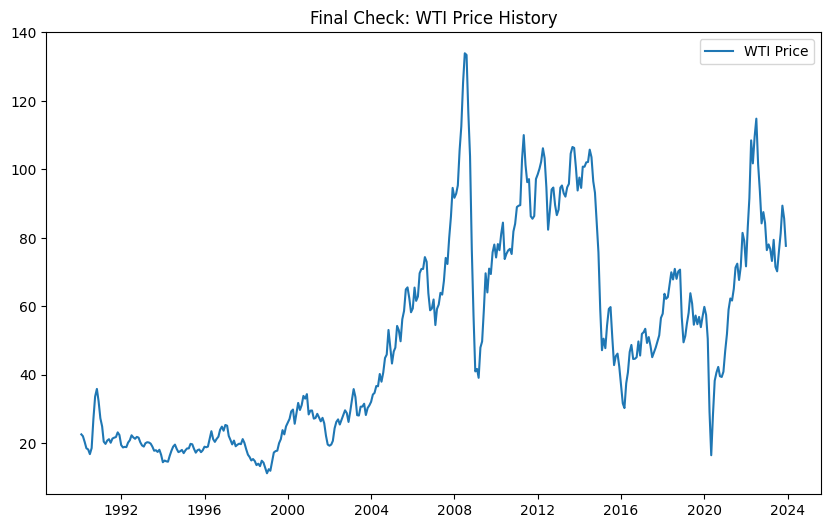

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import datetime
import requests
!pip install fredapi
from fredapi import Fred

# API Keys
import os
EIA_API_KEY = os.getenv("EIA_API_KEY", "YOUR_EIA_KEY_HERE")
FRED_API_KEY = os.getenv("FRED_API_KEY", "YOUR_FRED_KEY_HERE")

# Initialize FRED API
fred = Fred(api_key=FRED_API_KEY)

def fetch_eia_v2_steo(series_id, api_key):
    """
    Fetches data from the new EIA API v2.
    """
    facet_id = series_id.replace('STEO.', '').replace('.M', '')
    url = "https://api.eia.gov/v2/steo/data/"

    params = {
        "api_key": api_key, "frequency": "monthly", "data[0]": "value",
        "facets[seriesId][]": facet_id, "sort[0][column]": "period",
        "sort[0][direction]": "desc", "offset": 0, "length": 5000
    }

    try:
        r = requests.get(url, params=params)
        r.raise_for_status()
        data = r.json()

        if 'response' in data and 'data' in data['response']:
            df = pd.DataFrame(data['response']['data'])
            # Clean Dates and Values
            df['date'] = pd.to_datetime(df['period'])
            df.set_index('date', inplace=True)
            df = df[['value']].rename(columns={'value': series_id})
            df[series_id] = pd.to_numeric(df[series_id], errors='coerce')

            # Resample to Month End aligning with FRED
            return df.resample('ME').last()
        return pd.DataFrame()

    except Exception as e:
        print(f"   [!] Failed to fetch {series_id}: {e}")
        return pd.DataFrame()

# 3. OPTIMIZED VARIABLE LISTS
# We removed the broken 'RGDP' and 'FOREX' variables from EIA
# and added their substitutes to the FRED list below.

# STUDENT A: Macro (EIA only)
vars_eia = [
    'STEO.PAPR_OPEC.M',       # OPEC Production
    'STEO.PAPR_NONOPEC.M',    # Non-OPEC Production
    'STEO.COPS_OPEC.M',       # OPEC Spare Capacity
    'STEO.COPC_OPEC.M',       # OPEC Consumption
    'STEO.PASC_OECD_T3.M',    # OECD Inventory
    'STEO.COPRPUS.M',         # US Crude Production
    'STEO.CORIPUS.M',         # US Imports
    'STEO.T3_STCHANGE_OOECD.M', # Stock Change OECD
    'STEO.T3_STCHANGE_NOECD.M'  # Stock Change Non-OECD
]

# STUDENT B & C: FRED Variables (Including Substitutes)
vars_fred = [
    'IPG211S',      # Industrial Production: Oil and Gas
    'CAPUTLG211S',  # Capacity Utilization
    'PCU211211',    # PPI Crude Petroleum
    'WTISPLC',      # Spot Crude Price (Target)
    'CPIENGSL',     # CPI Energy
    # REPLACEMENTS FOR BROKEN EIA VARIABLES:
    'DTWEXBGS',     # Trade Weighted US Dollar (Replaces STEO.FOREX_WORLD)
    'INDPRO'        # Industrial Production Index (Replaces STEO.RGDP)
]

# 4. EXECUTION
data_merge = []

print("--- Starting Optimized Data Collection ---")

# A. Fetch EIA Data
print(f"Fetching {len(vars_eia)} EIA Variables...")
for var in vars_eia:
    df = fetch_eia_v2_steo(var, EIA_API_KEY)
    if not df.empty:
        data_merge.append(df)
    else:
        print(f"   -> Warning: {var} returned empty.")

# B. Fetch FRED Data
print(f"Fetching {len(vars_fred)} FRED Variables...")
for var in vars_fred:
    try:
        s = fred.get_series(var)
        df = pd.DataFrame(s, columns=[var]).resample('ME').last()
        data_merge.append(df)
    except Exception as e:
        print(f"   -> Warning: Failed to fetch {var}: {e}")

# C. Merge & Clean
print("\nMerging and Cleaning...")
if data_merge:
    # 1. Outer Join
    final_df = pd.concat(data_merge, axis=1, join='outer').sort_index()

    # 2. TRIM DATES (Crucial Step!)
    # We remove data before 1990 and AFTER 2023 to avoid future predictions
    final_df = final_df['1990-01-01':'2023-12-31']

    # 3. Fill Missing Values (Modern Pandas Method)
    final_df = final_df.bfill().ffill()

    # 4. Create Forecast Target
    final_df['forecast'] = final_df['WTISPLC'].shift(-1)
    final_df.dropna(inplace=True)

    # D. Save
    print(f"SUCCESS. Final Dataset Shape: {final_df.shape}")
    print(f"Date Range: {final_df.index[0].date()} to {final_df.index[-1].date()}")

    final_df.to_csv('oil_market_data_complete.csv')
    print("\nSaved to 'oil_market_data_complete.csv'")

    # E. Quick Plot check
    plt.figure(figsize=(10, 6))
    plt.plot(final_df.index, final_df['WTISPLC'], label='WTI Price')
    plt.title("Final Check: WTI Price History")
    plt.legend()
    plt.show()

else:
    print("CRITICAL ERROR: No data fetched.")

--- Starting Step 5: EDA & Quality Check ---
Loaded dataset: (407, 17)


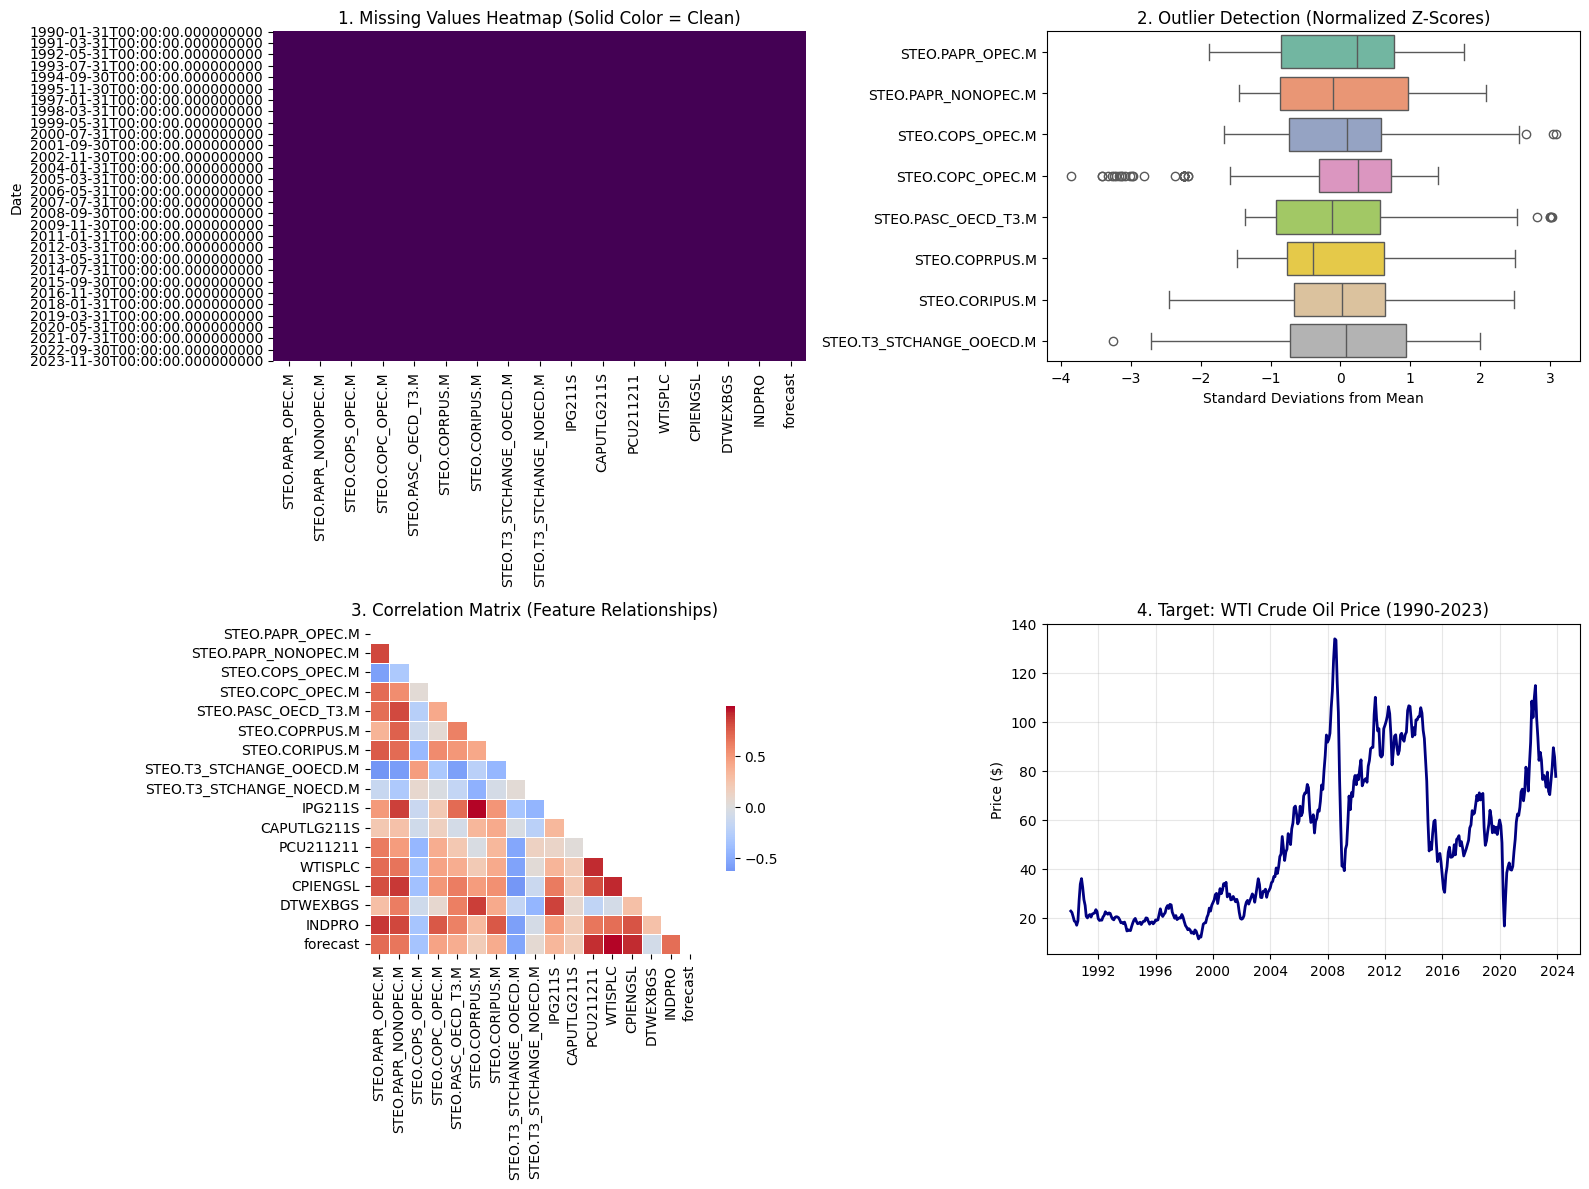


SUCCESS: Plots generated and saved as 'Step5_Data_Cleaning_Report.png'.


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# STEP 5: DATA CLEANING VISUALIZATION
print("--- Starting Step 5: EDA & Quality Check ---")

# 1. Load the "Sterilized" Data
try:
    df = pd.read_csv('oil_market_data_complete.csv', index_col=0, parse_dates=True)
    print(f"Loaded dataset: {df.shape}")
except FileNotFoundError:
    print("Error: Run Step 3 first to generate 'oil_market_data_complete.csv'")

# 2. GENERATE REPORT PLOTS
# We create a 2x2 grid to fit all required charts in one image
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot A: Missing Values Heatmap
# Requirement: Prove there are no "holes" in the data.
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', ax=axes[0, 0])
axes[0, 0].set_title('1. Missing Values Heatmap (Solid Color = Clean)')
axes[0, 0].set_ylabel('Date')

# Plot B: Outlier Boxplots
# Requirement: "Student A (Outliers)" - Show extreme market events.
# We normalize the data (Z-Score) just for this plot so variables share the same scale.
df_norm = (df - df.mean()) / df.std()
sns.boxplot(data=df_norm.iloc[:, :8], orient="h", palette="Set2", ax=axes[0, 1])
axes[0, 1].set_title('2. Outlier Detection (Normalized Z-Scores)')
axes[0, 1].set_xlabel('Standard Deviations from Mean')

# Plot C: Correlation Matrix
# Requirement: "Student B (Bad Data)" - Show variable relationships.
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool)) # Mask upper triangle for readability
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, square=True,
            linewidths=.5, cbar_kws={"shrink": .5}, ax=axes[1, 0])
axes[1, 0].set_title('3. Correlation Matrix (Feature Relationships)')

# Plot D: Target Variable History
# Requirement: "Student B (Time Series)"
axes[1, 1].plot(df.index, df['WTISPLC'], color='navy', linewidth=2)
axes[1, 1].set_title('4. Target: WTI Crude Oil Price (1990-2023)')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_ylabel('Price ($)')

plt.tight_layout()
plt.savefig('Step5_Data_Cleaning_Report.png') # Saves the image for your PDF
plt.show()

print("\nSUCCESS: Plots generated and saved as 'Step5_Data_Cleaning_Report.png'.")

--- Starting Step 7: Exploratory Data Analysis ---
1. Generated 'Student_A_Distributions.png'


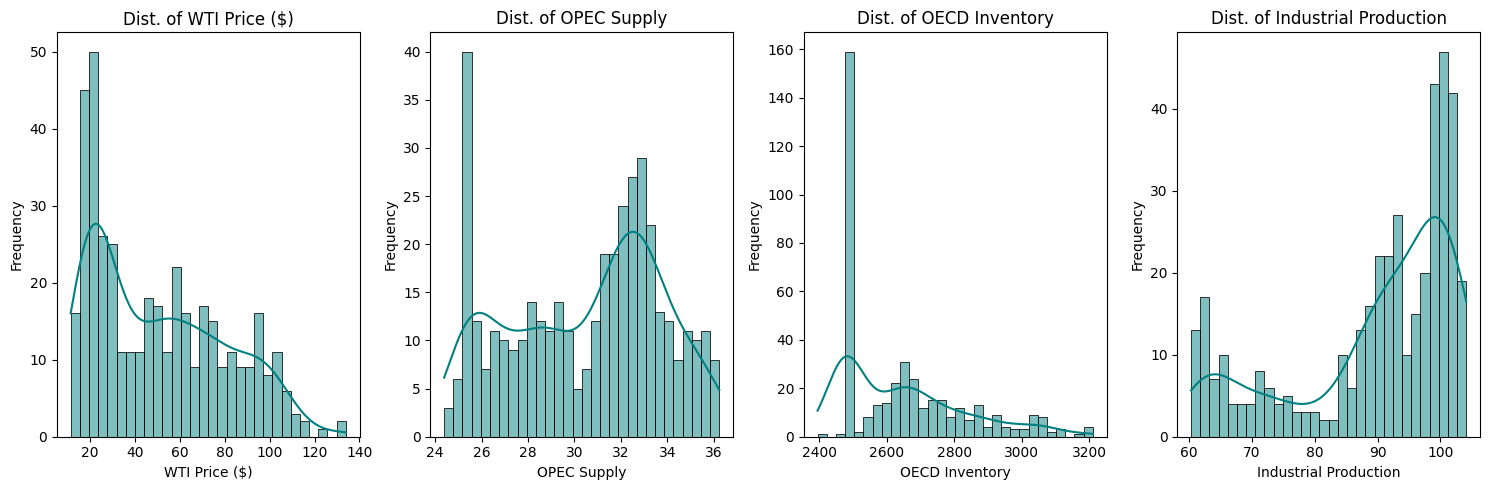

2. Generated 'Student_B_TimeSeries.png'


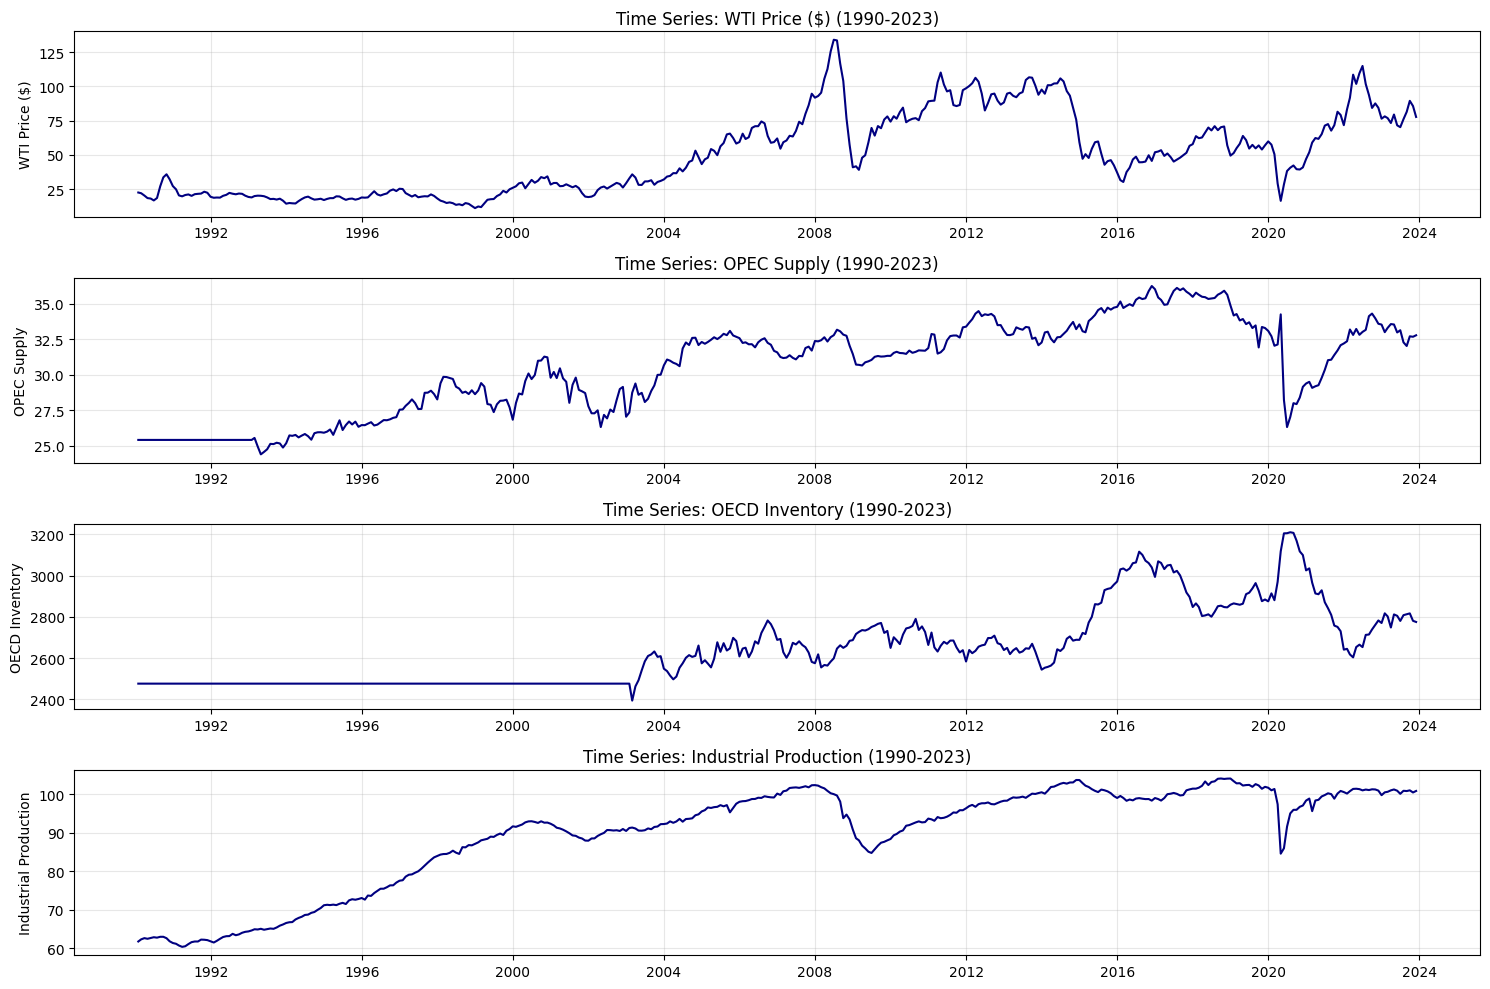

3. Generated 'Student_C_Multivariate_Scatter.png'


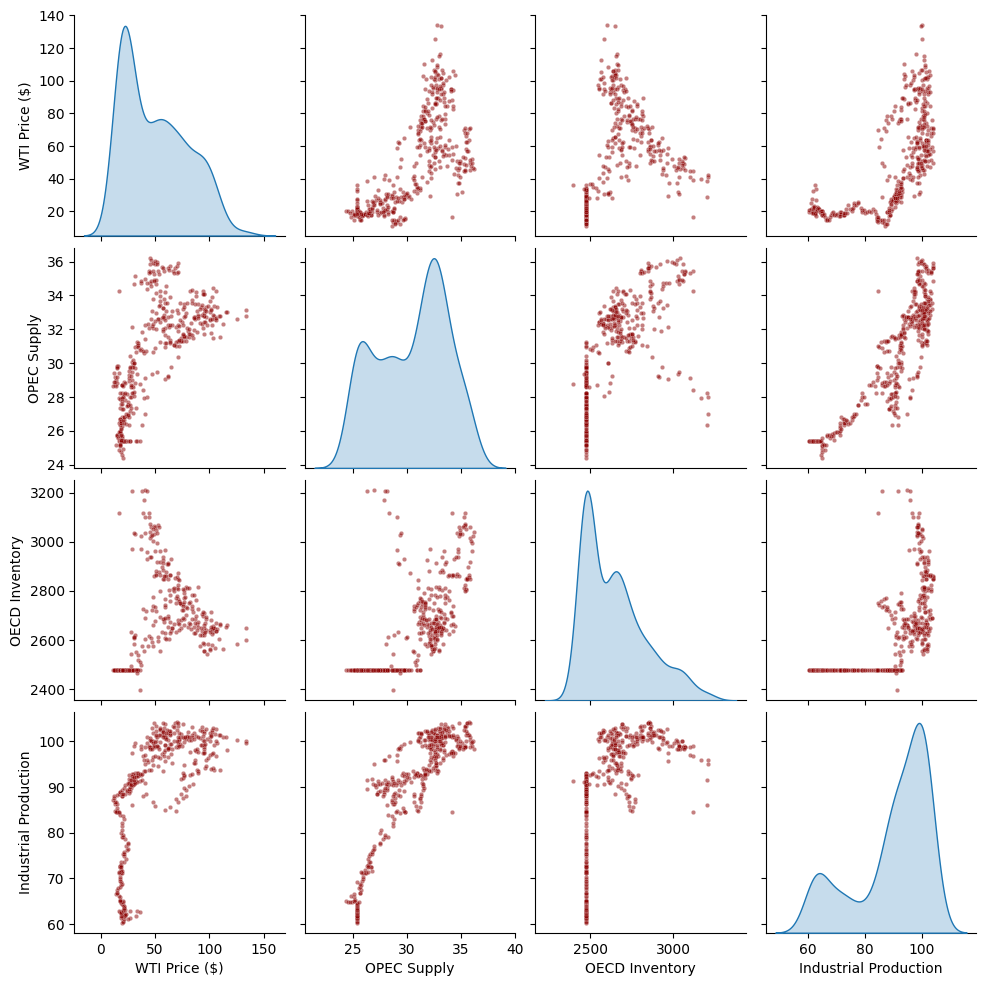

4. Generated 'Student_C_Correlation.png'


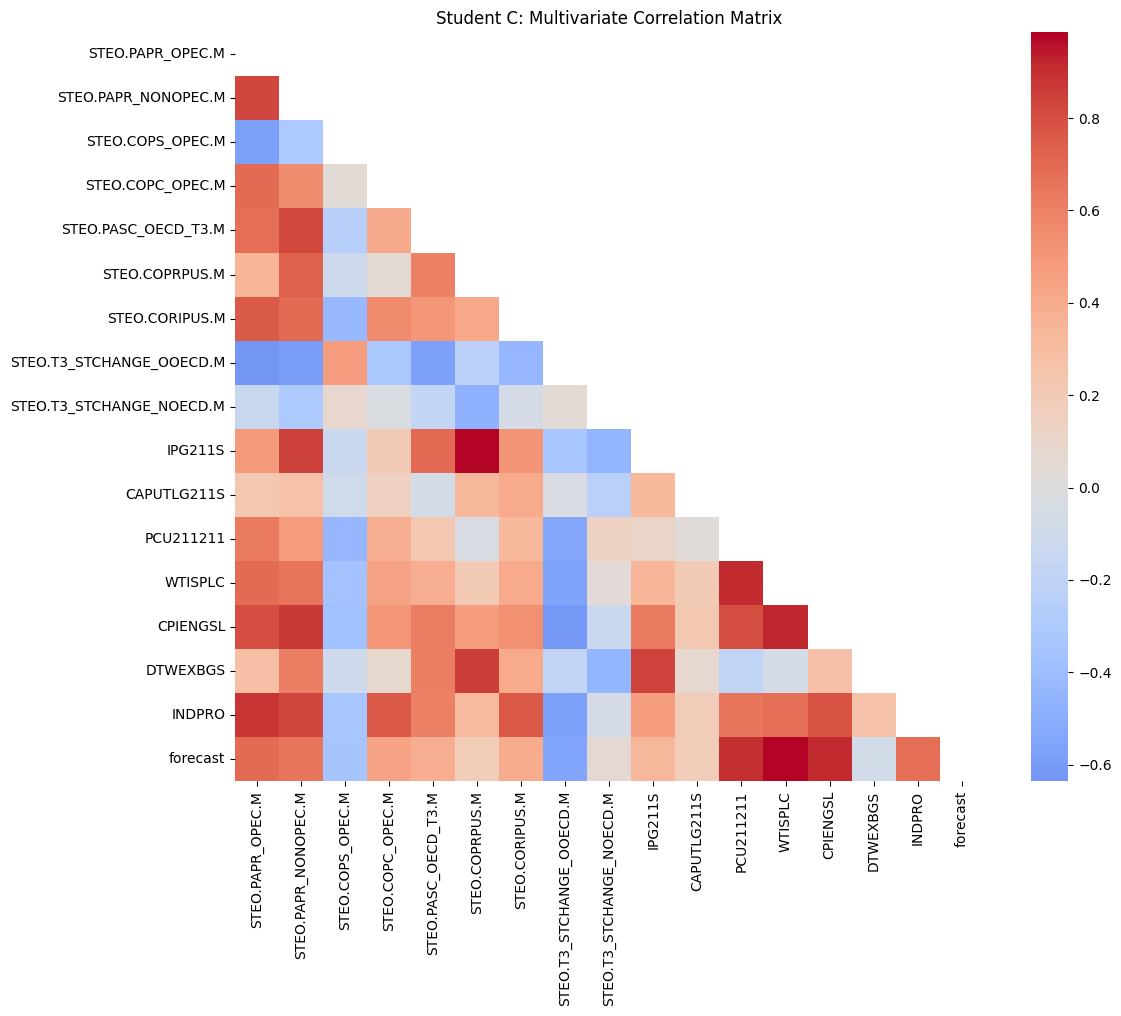


All Step 7 plots saved successfully.


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# SETUP: LOAD DATA
print("--- Starting Step 7: Exploratory Data Analysis ---")

# Load your sterilized dataset
df = pd.read_csv('oil_market_data_complete.csv', index_col=0, parse_dates=True)
key_vars = {
    'WTISPLC': 'WTI Price ($)',
    'STEO.PAPR_OPEC.M': 'OPEC Supply',
    'STEO.PASC_OECD_T3.M': 'OECD Inventory',
    'INDPRO': 'Industrial Production'
}

# Subset data for plotting
plot_data = df[list(key_vars.keys())].rename(columns=key_vars)

# 1. STUDENT A: DISTRIBUTIONAL PLOTS
plt.figure(figsize=(15, 5))

for i, col in enumerate(plot_data.columns):
    plt.subplot(1, 4, i+1)
    sns.histplot(plot_data[col], kde=True, color='teal', bins=30)
    plt.title(f'Dist. of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.savefig('Student_A_Distributions.png')
print("1. Generated 'Student_A_Distributions.png'")
plt.show()

# 2. STUDENT B: TIME SERIES PLOTS
plt.figure(figsize=(15, 10))

for i, col in enumerate(plot_data.columns):
    plt.subplot(4, 1, i+1)
    plt.plot(plot_data.index, plot_data[col], color='navy', linewidth=1.5)
    plt.title(f'Time Series: {col} (1990-2023)')
    plt.ylabel(col)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('Student_B_TimeSeries.png')
print("2. Generated 'Student_B_TimeSeries.png'")
plt.show()

# 3. STUDENT C: MULTIVARIATE PLOTS

# Part 1: Pairplot (Scatter Matrix)
sns.pairplot(plot_data, diag_kind='kde', plot_kws={'alpha': 0.5, 's': 10, 'color': 'darkred'})
plt.savefig('Student_C_Multivariate_Scatter.png')
print("3. Generated 'Student_C_Multivariate_Scatter.png'")
plt.show()

# Part 2: Detailed Correlation Heatmap (All variables)
plt.figure(figsize=(12, 10))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Hide upper triangle
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm', center=0, square=True)
plt.title('Student C: Multivariate Correlation Matrix')
plt.tight_layout()
plt.savefig('Student_C_Correlation.png')
print("4. Generated 'Student_C_Correlation.png'")
plt.show()

print("\nAll Step 7 plots saved successfully.")